In [1]:
# Assume that we have a text file locally.
f = open("cs621_text_data_1.txt")

In [2]:
# Store each line in data_raw[].
data_raw = []
f.seek(0)
for line in f:
    line = line.strip()
    line = line.replace(".", "")
    line = line.replace(",", "")
    data_raw.append(line)
f.close()

In [3]:
print(data_raw)

['Data science is a great subject to study', 'Software programming is fun', 'I love both data and computer programming', 'CS617 is programming for data science']


In [4]:
# processed words will be stored in data[].
data = []
for i in range(len(data_raw)):
    words = data_raw[i].split()
    for w in words:
        w = w.lower()
        data.append(w)

In [5]:
# Store only distinct words
data_distinct = list(set(data))

In [6]:
print(data_distinct)

['a', 'both', 'cs617', 'fun', 'and', 'i', 'subject', 'great', 'to', 'is', 'programming', 'data', 'love', 'study', 'software', 'science', 'for', 'computer']


In [7]:
#word_freq is a dictionary used to store the word freqs.
word_freq = {}
for w in data_distinct:
    word_freq[w] = 0

In [8]:
# Compute each word's freq via two for loops.
for i in range(len(data_distinct)):
    key_word = data_distinct[i]
    count = 0
    for w in data:
        if w == key_word:
            count = count + 1
    word_freq[key_word] = count

In [9]:
print(word_freq)

{'a': 1, 'both': 1, 'cs617': 1, 'fun': 1, 'and': 1, 'i': 1, 'subject': 1, 'great': 1, 'to': 1, 'is': 3, 'programming': 3, 'data': 3, 'love': 1, 'study': 1, 'software': 1, 'science': 2, 'for': 1, 'computer': 1}


In [10]:
#It would be nice to see the words in alphabetical order. Let's create a Pandas Series object. 
import pandas as pd
word_freq_series = pd.Series(word_freq)
word_freq_series.sort_index(inplace=True)

/var/folders/qr/r5_np_gs4ss7zw687hsrwgbr0000gn/T/ipykernel_12691/1973304917.py:4: Pandas4Warning: The inplace keyword in Series.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  word_freq_series.sort_index(inplace=True)


In [11]:
print(word_freq_series)

a              1
and            1
both           1
computer       1
cs617          1
data           3
for            1
fun            1
great          1
i              1
is             3
love           1
programming    3
science        2
software       1
study          1
subject        1
to             1
dtype: int64


In [12]:
# Sort the Series by its values.
word_freq_series.sort_values(ascending = False, inplace=True)

/var/folders/qr/r5_np_gs4ss7zw687hsrwgbr0000gn/T/ipykernel_12691/105562918.py:2: Pandas4Warning: The inplace keyword in Series.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  word_freq_series.sort_values(ascending = False, inplace=True)


In [13]:
print(word_freq_series)

is             3
data           3
programming    3
science        2
a              1
subject        1
study          1
software       1
love           1
i              1
and            1
great          1
fun            1
for            1
cs617          1
computer       1
both           1
to             1
dtype: int64


In [14]:
# Let's create a dataframe with same values.
df = word_freq_series.sort_values(ascending = False).to_frame(name="freq").reset_index()

In [15]:
df

,index,freq
0,is,3
1,programming,3
2,data,3
3,science,2
4,great,1
5,both,1
6,computer,1
7,cs617,1
8,for,1
9,fun,1


In [16]:
# In needed, save the dataframe to a local file.
df.to_csv("word_freq.csv", index=False)

In [17]:
data

['data',
 'science',
 'is',
 'a',
 'great',
 'subject',
 'to',
 'study',
 'software',
 'programming',
 'is',
 'fun',
 'i',
 'love',
 'both',
 'data',
 'and',
 'computer',
 'programming',
 'cs617',
 'is',
 'programming',
 'for',
 'data',
 'science']

In [18]:
word_freq_series_2 = pd.Series(data)

In [19]:
print(word_freq_series_2)

0            data
1         science
2              is
3               a
4           great
5         subject
6              to
7           study
8        software
9     programming
10             is
11            fun
12              i
13           love
14           both
15           data
16            and
17       computer
18    programming
19          cs617
20             is
21    programming
22            for
23           data
24        science
dtype: str


In [20]:
word_freq_series_2.value_counts()

data           3
is             3
programming    3
science        2
a              1
great          1
subject        1
to             1
study          1
software       1
fun            1
i              1
love           1
both           1
and            1
computer       1
cs617          1
for            1
Name: count, dtype: int64

In [21]:
df2 = pd.DataFrame(data)

In [22]:
df2

,0
0,data
1,science
2,is
3,a
4,great
5,subject
6,to
7,study
8,software
9,programming


In [23]:
df2.columns = ['word']

In [24]:
df2

,word
0,data
1,science
2,is
3,a
4,great
5,subject
6,to
7,study
8,software
9,programming


In [25]:
df2["word"].value_counts()

word
data           3
is             3
programming    3
science        2
a              1
great          1
subject        1
to             1
study          1
software       1
fun            1
i              1
love           1
both           1
and            1
computer       1
cs617          1
for            1
Name: count, dtype: int64

In [26]:
type(df2["word"].value_counts())

pandas.Series

In [27]:
df_3 = pd.DataFrame(df2["word"].value_counts()).reset_index()

In [28]:
df_3

,word,count
0,data,3
1,is,3
2,programming,3
3,science,2
4,a,1
5,great,1
6,subject,1
7,to,1
8,study,1
9,software,1


In [29]:
df_3.columns=['word', 'freq']

In [30]:
df_3

,word,freq
0,data,3
1,is,3
2,programming,3
3,science,2
4,a,1
5,great,1
6,subject,1
7,to,1
8,study,1
9,software,1


In [31]:
# Blank cell

In [32]:
#Assume the following was given, or computed by ourselves.
words_to_plot = ['data', 'science', 'text', 'analytics', 'software']
importances = [280, 240, 200, 160, 120]

In [33]:
import matplotlib.pyplot as plt

In [34]:
word = 'Science'

Text(0.5, 0.5, 'Science')

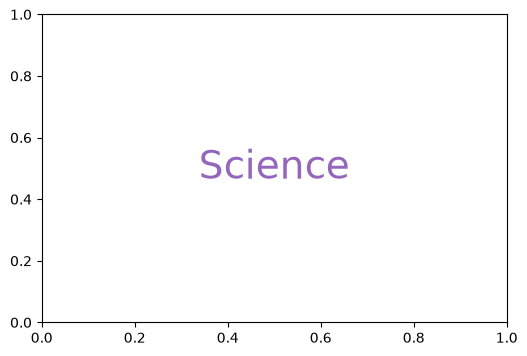

In [76]:
plt.subplots(figsize=(6, 4))
text_kwargs = dict(ha='center', va='center', fontsize=28, color='C4')
plt.text(0.5, 0.5, word,**text_kwargs)

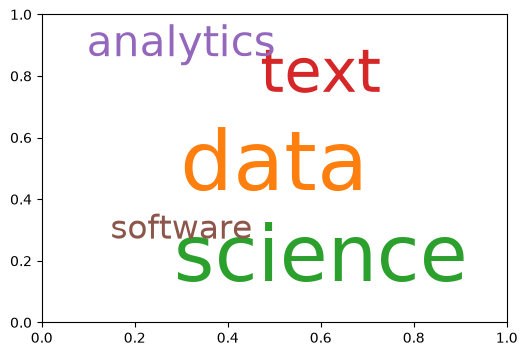

In [36]:
#Let's plot the given word list.
words_to_plot = ['data', 'science', 'text', 'analytics', 'software']
importances = [60, 56 , 44, 30, 24]
plt.subplots(figsize=(6, 4))
text_kwargs = dict(ha='center', va='center', fontsize= importances[0], color='C1')
#plt.text(3, 2, words_to_plot[0],ha='center', va='center', fontsize=28, color='C1')
plt.text(0.5, 0.5, words_to_plot[0],**text_kwargs)
text_kwargs = dict(ha='center', va='center', fontsize=importances[1], color='C2')
plt.text(0.6, 0.2, words_to_plot[1],**text_kwargs)
text_kwargs = dict(ha='center', va='center', fontsize=importances[2], color='C3')
plt.text(0.6, 0.8, words_to_plot[2],**text_kwargs)
text_kwargs = dict(ha='center', va='center', fontsize=importances[3], color='C4')
plt.text(0.3, 0.9, words_to_plot[3],**text_kwargs)
text_kwargs = dict(ha='center', va='center', fontsize=importances[4], color='C5')
plt.text(0.3, 0.3, words_to_plot[4],**text_kwargs)
plt.show()

In [37]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

In [38]:
# Load the US constitution text file.
text = open("constitution.txt").read()

In [39]:
# Create a word cloud out of US constitution. 
wordcloud = WordCloud(width = 600, height = 400).generate(text)

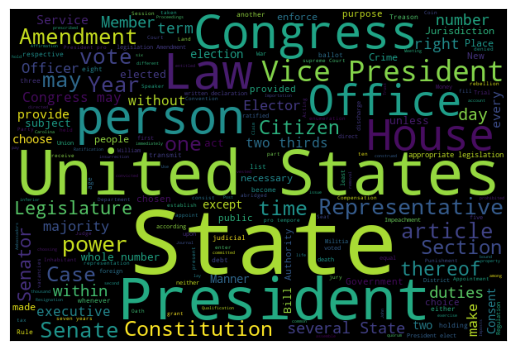

In [40]:
# Show the word cloud as an image. 
plt.tick_params(top=False, bottom=False, left=False, right=False,
                labelleft=False, labelbottom=False)
plt.imshow(wordcloud)

In [41]:
# Use a different background color.
wordcloud2= WordCloud(max_font_size=60, max_words=16, background_color="white").generate(text)

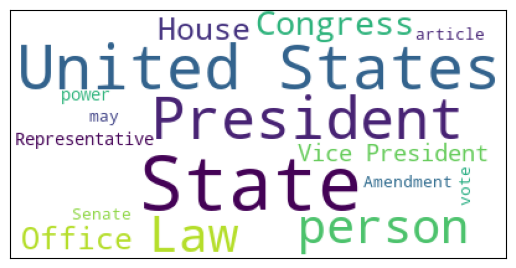

In [42]:
plt.tick_params(top=False, bottom=False, left=False, right=False,
                labelleft=False, labelbottom=False)
plt.imshow(wordcloud2)

In [43]:
word_freq

{'a': 1,
 'both': 1,
 'cs617': 1,
 'fun': 1,
 'and': 1,
 'i': 1,
 'subject': 1,
 'great': 1,
 'to': 1,
 'is': 3,
 'programming': 3,
 'data': 3,
 'love': 1,
 'study': 1,
 'software': 1,
 'science': 2,
 'for': 1,
 'computer': 1}

In [44]:
# Create a different dictionary with various values. 
my_freq = {}
for i in range(len(words_to_plot)):
    my_freq[words_to_plot[i]] = importances[i]

In [45]:
my_freq

{'data': 60, 'science': 56, 'text': 44, 'analytics': 30, 'software': 24}

In [46]:
# Create a word cloud out of a word-freq dictionary.
wordcloud4= WordCloud(max_font_size=200, stopwords = None, max_words=20, background_color="white").generate_from_frequencies(my_freq)

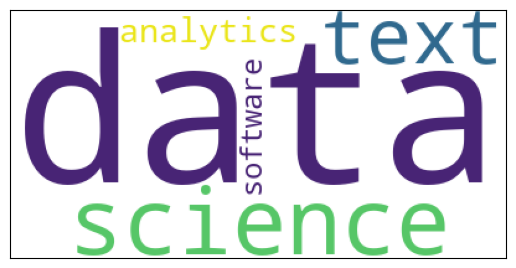

In [47]:
# Show the image. 
plt.tick_params(top=False, bottom=False, left=False, right=False,
                labelleft=False, labelbottom=False)
plt.imshow(wordcloud4)

In [48]:
# Load numpy and Image libraries. 
import numpy as np
from PIL import Image

In [49]:
# Use a different background color. 
wordcloud4= WordCloud(max_font_size=200, stopwords = None, max_words=20, background_color="brown").generate_from_frequencies(my_freq)

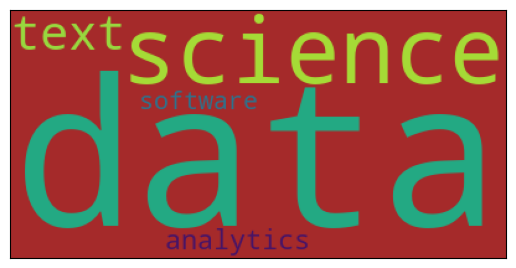

In [50]:
plt.tick_params(top=False, bottom=False, left=False, right=False,
                labelleft=False, labelbottom=False)
plt.imshow(wordcloud4)

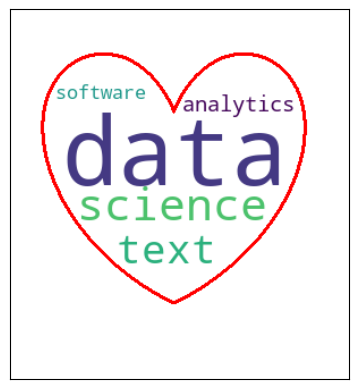

In [51]:
# Create a word cloud with my own mask. 
mask = np.array(Image.open("heart.png"))
wordcloud4= WordCloud(width = 300, height = 200, mask=mask,contour_color='red',contour_width=3 , max_font_size=200, stopwords = None, max_words=20, background_color="white").generate_from_frequencies(my_freq)
plt.figure()
plt.imshow(wordcloud4, interpolation = "bilinear")
plt.tick_params(top=False, bottom=False, left=False, right=False,
                labelleft=False, labelbottom=False)
#plt.imshow(wordcloud4)
plt.show()

In [52]:
# Check the values in a mask. 255 represents color white; 0 represents color black. 
mask

array([[[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       ...,

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]]

In [53]:
# Blank cell

In [54]:
# Import pos_tag and word_takenize in nltk.
from nltk import pos_tag, word_tokenize

In [83]:
# Open a local text file. 
f = open("cs621_text_data_1.txt")

In [56]:
# Load the text into a list.
data_raw = []
f.seek(0)
for line in f:
    data_raw.append(line)
f.close()

In [57]:
data_raw

['Data science is a great subject to study.\n',
 'Software programming is fun.\n',
 'I love both data and computer programming. \n',
 'CS617 is programming for data science.']

In [58]:
# Find out the pos tag for each word. 
import nltk
nltk.download('averaged_perceptron_tagger_eng')
pos_tags=[]
for sen in data_raw:
    sen = sen.strip()
    pos = pos_tag(word_tokenize(sen))
    pos_tags.append(pos)

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /Users/leo/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


In [59]:
# A word, pos_tag is stored as a tuple. 
pos_tags

[[('Data', 'NNP'),
  ('science', 'NN'),
  ('is', 'VBZ'),
  ('a', 'DT'),
  ('great', 'JJ'),
  ('subject', 'NN'),
  ('to', 'TO'),
  ('study', 'NN'),
  ('.', '.')],
 [('Software', 'NNP'),
  ('programming', 'NN'),
  ('is', 'VBZ'),
  ('fun', 'NN'),
  ('.', '.')],
 [('I', 'PRP'),
  ('love', 'VBP'),
  ('both', 'DT'),
  ('data', 'NNS'),
  ('and', 'CC'),
  ('computer', 'NN'),
  ('programming', 'NN'),
  ('.', '.')],
 [('CS617', 'NNP'),
  ('is', 'VBZ'),
  ('programming', 'VBG'),
  ('for', 'IN'),
  ('data', 'NNS'),
  ('science', 'NN'),
  ('.', '.')]]

In [60]:
# Store the pos tag in a list. 
all_tags=[]
for l in pos_tags:
    for p in l:
        print(p[1])
        all_tags.append(p[1])

NNP
NN
VBZ
DT
JJ
NN
TO
NN
.
NNP
NN
VBZ
NN
.
PRP
VBP
DT
NNS
CC
NN
NN
.
NNP
VBZ
VBG
IN
NNS
NN
.


In [61]:
len(all_tags)

29

In [62]:
# Get the distinct pos tags. 
distinct_tags = set(all_tags)

In [63]:
distinct_tags

{'.',
 'CC',
 'DT',
 'IN',
 'JJ',
 'NN',
 'NNP',
 'NNS',
 'PRP',
 'TO',
 'VBG',
 'VBP',
 'VBZ'}

In [64]:
# Remove the . tag.
distinct_tags_list = []
for w in distinct_tags:
    if w.isalpha() == True:
        distinct_tags_list.append(w)

In [65]:
# All distinct pos tags. 
distinct_tags_list

['VBZ', 'PRP', 'NNS', 'NNP', 'TO', 'NN', 'DT', 'VBG', 'JJ', 'CC', 'IN', 'VBP']

In [66]:
len(distinct_tags_list)

12

In [67]:
# Create a dictionary with each distinct pos tag as a key with value 0.
tag_freq={}
for tag in distinct_tags_list:
    tag_freq[tag] = 0
    

In [68]:
# Compute the frequeny value of each pos tag. 
for tag_u in distinct_tags_list:
    for tag in all_tags:
        if tag == tag_u:
            tag_freq[tag_u] =  tag_freq[tag_u] + 1

In [69]:
tag_freq

{'VBZ': 3,
 'PRP': 1,
 'NNS': 2,
 'NNP': 3,
 'TO': 1,
 'NN': 8,
 'DT': 2,
 'VBG': 1,
 'JJ': 1,
 'CC': 1,
 'IN': 1,
 'VBP': 1}

In [70]:
# Create a Series object out put pos tag freq dictionary.
ser_tag = pd.Series(tag_freq)

In [71]:
# Sort the Series by the values, in descending order. 
ser_tag.sort_values(ascending=False, inplace = True)

/var/folders/qr/r5_np_gs4ss7zw687hsrwgbr0000gn/T/ipykernel_12691/1406276103.py:2: Pandas4Warning: The inplace keyword in Series.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  ser_tag.sort_values(ascending=False, inplace = True)


In [72]:
ser_tag

NN     8
VBZ    3
NNP    3
NNS    2
DT     2
PRP    1
TO     1
VBG    1
JJ     1
CC     1
IN     1
VBP    1
dtype: int64

In [73]:
# Only use the first 6 pos tags.
ser_tag[:6]

NN     8
VBZ    3
NNP    3
NNS    2
DT     2
PRP    1
dtype: int64

<Axes: >

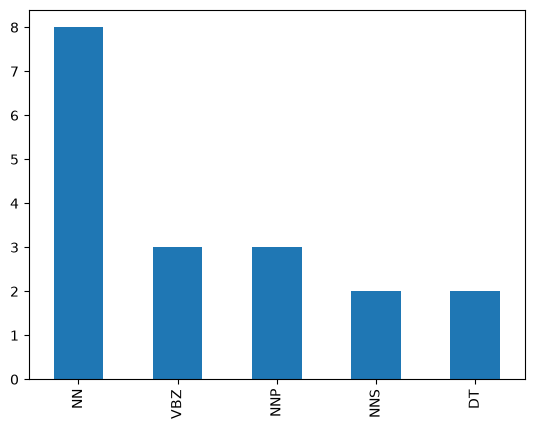

In [74]:
# Show them as a bar chart. 
ser_tag[:5].plot.bar()

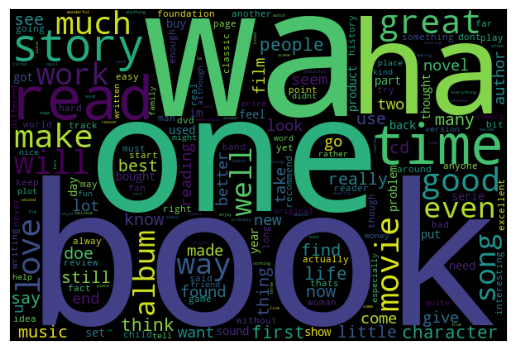

In [77]:
#Homework

# Load Module 11 results
text = open("module_11_results.txt").read()

wordcloud = WordCloud(width = 600, height = 400).generate(text)

# Show the word cloud as an image. 
plt.tick_params(top=False, bottom=False, left=False, right=False,
                labelleft=False, labelbottom=False)
plt.imshow(wordcloud)

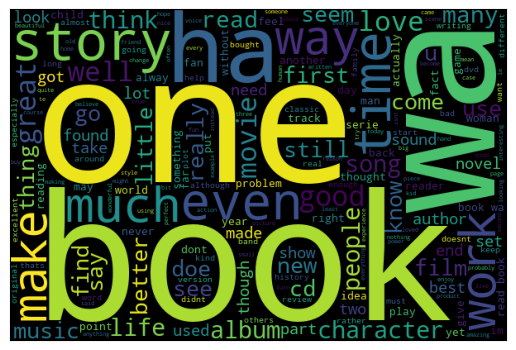

In [82]:
from nltk.corpus import stopwords 
english_stop_words = stopwords.words('English')
# 1. Tokenize and convert to lowercase
tokens = word_tokenize(text.lower())

# 2. Load English stop words
stop_words = set(stopwords.words("english"))

# 3. Filter out stop words
filtered_tokens = [word for word in tokens if word not in stop_words]

# 4. Optional: Join back into a string
text = " ".join(filtered_tokens)


wordcloud = WordCloud(width = 600, height = 400).generate(text)

# Show the word cloud as an image. 
plt.tick_params(top=False, bottom=False, left=False, right=False,
                labelleft=False, labelbottom=False)
plt.imshow(wordcloud)

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /Users/leo/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


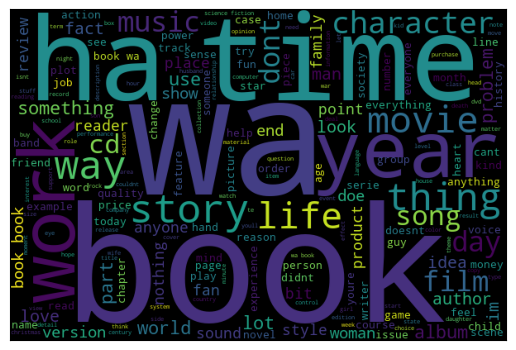

In [97]:
# Apply POS Tagging on the dataset and only keep words tagged with NN and NNP.
import nltk
nltk.download('averaged_perceptron_tagger_eng')

pos = pos_tag(word_tokenize(text))

filtered_words = [word for word, tag in pos if tag in ('NN', 'NNP')]
new_text = " ".join(filtered_words)

wordcloud = WordCloud(width = 600, height = 400).generate(new_text)

# Show the word cloud as an image. 
plt.tick_params(top=False, bottom=False, left=False, right=False,
                labelleft=False, labelbottom=False)
plt.imshow(wordcloud)